## C-Trap Kymograph position analysis 
Artur Kaczmarczyk 

version: 31st October 2026 | Artur Kaczmarczyk | github.com/arturrsl2
Single-Molecule Biophysics Facility | IBB PAS Warsaw

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")
from kymo_tools import *


### Load .h5 file

In [380]:
h5_path = "../data/2nM_60nt_ssDNA_2nM_MgCl2_gapped 20260806-173315 Kymograph M15_control_ssDNAonly_40pN.h5"
file = load_h5(h5_path)

list_kymos(file)

import os
safe_basename = os.path.splitext(os.path.basename(h5_path))[0].replace(" ", "_").replace(":", "-")
print(f"Base name: {safe_basename}")

Base name: 2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-173315_Kymograph_M15_control_ssDNAonly_40pN


### Plot the kymograph

M15_control_ssDNAonly_40pN


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..13.0].


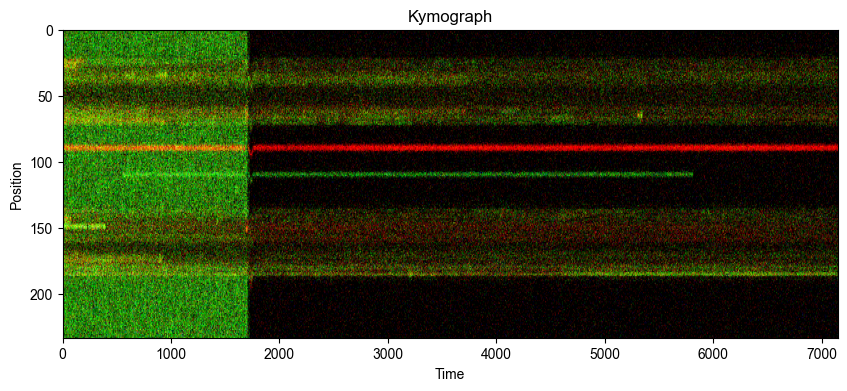

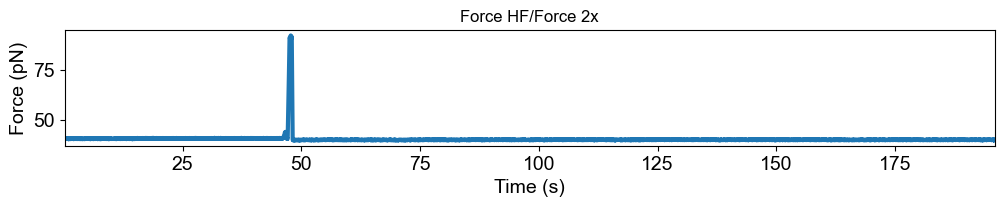

In [ ]:
kymo_name = list_kymos(file)[0]
print(kymo_name)

kymo = get_kymo(file, kymo_name)
plot_kymo(kymo, save_path="../results/kymo_raw.png", contrast="percentile",flip_y=False)
#plt.xlabel("Frame number")
#plt.ylabel("Position (px)")

#result = analyze_window(kymo, x_range=x_range, y_range=y_range, ..., flip_y=True)

#kymo_ds = kymo.downsampled_by(time_factor=10, position_factor=1)
#plot_kymo(kymo_ds, channel="green", save_path="../results/kymo_ds.png", contrast="percentile")

#plt.figure()
#kymo_ds_time.plot("rgb", adjustment=lk.ColorAdjustment(0, 98, mode="percentile"))
#plt.show()

line_timestamp_ranges = kymo.line_timestamp_ranges()
force = file.force2x

downsampled = force.downsampled_over(line_timestamp_ranges)



#plt.figure()
#force.plot(label="high frequency")
plt.figure(figsize=(12, 1.5))
ax = plt.gca()
downsampled.plot(start=force.start, linewidth = 3, label="downsampled force")


ax.tick_params(axis='both', labelsize=14)  # rozmiar cyfr na osiach
ax.xaxis.label.set_size(14)                # rozmiar podpisu osi X
ax.yaxis.label.set_size(14)   
ax.margins(x=0)
#ax.set_ylim(0, 40)
#ax.set_yticks(np.arange(0, 41, 20))
#ax.get_legend().remove()
#plt.legend()
#plt.show()

import pandas as pd
pd.DataFrame({
    "timestamp_ns": downsampled.timestamps,
    "force_pN": downsampled.data
}).to_csv("../results/force_downsampled.csv", index=False)

### Plot cummulative intensity

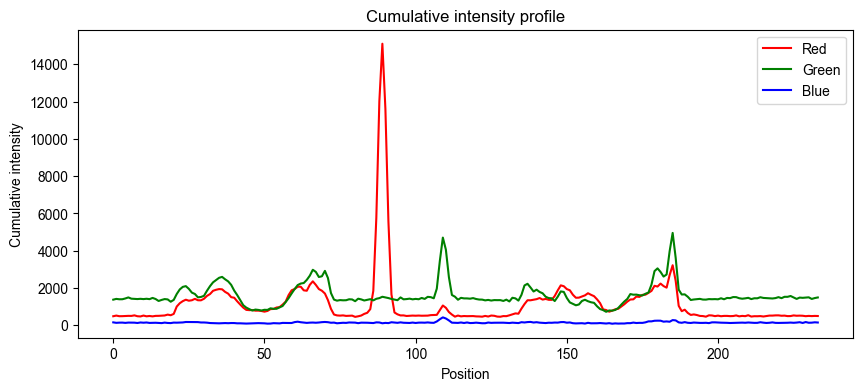

In [382]:
R, G, B = extract_rgb_cumulative_intensity(kymo, axis=1)

plt.figure(figsize=(10, 4))
plt.plot(R, color="red", label="Red")
plt.plot(G, color="green", label="Green")
plt.plot(B, color="blue", label="Blue")

plt.xlabel("Position")
plt.ylabel("Cumulative intensity")
plt.title("Cumulative intensity profile")
plt.legend()
plt.show()

### Chop the desired fragment of the kymograph

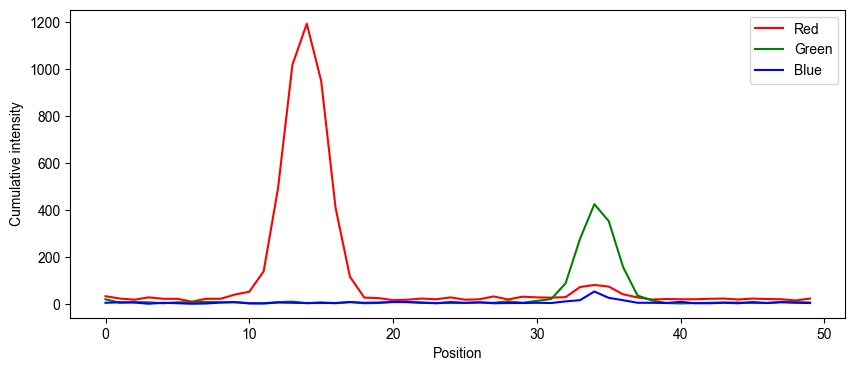

../results/M15_control_ssDNAonly_40pN_y75-125_x2000-2700_zfull_rgb_intensity.png
../results/M15_control_ssDNAonly_40pN_y75-125_x2000-2700_zfull_rgb_intensity.csv


In [407]:
image = kymo.get_image(channel="rgb")

# wybierasz fragment kymografu
y_range = (75,125)
x_range = (2000,2700)
z_range = None

y_slice = slice(None) if y_range is None else slice(y_range[0], y_range[1])
x_slice = slice(None) if x_range is None else slice(x_range[0], x_range[1])
z_slice = slice(None) if z_range is None else slice(z_range[0], z_range[1])

sub = image[y_slice, x_slice, z_slice]

R, G, B = extract_rgb_cumulative_intensity(sub, axis=1)

plt.figure(figsize=(10, 4))
plt.plot(R, color="red", label="Red")
plt.plot(G, color="green", label="Green")
plt.plot(B, color="blue", label="Blue")
plt.xlabel("Position")
plt.ylabel("Cumulative intensity")
plt.legend()
plt.show()

png_path = export_rgb_intensity_plot(
    R, G, B,
    kymo_name=kymo_name,
    coords={"y": y_range, "x": x_range, "z": z_range}
)

print(png_path)

csv_path = export_rgb_intensity_csv(
    R, G, B,
    kymo_name=kymo_name,
    coords={"y": y_range, "x": x_range, "z": z_range}
)

print(csv_path)

### Co-plot intensities from multiple files (optional)

Found 9 CSV files


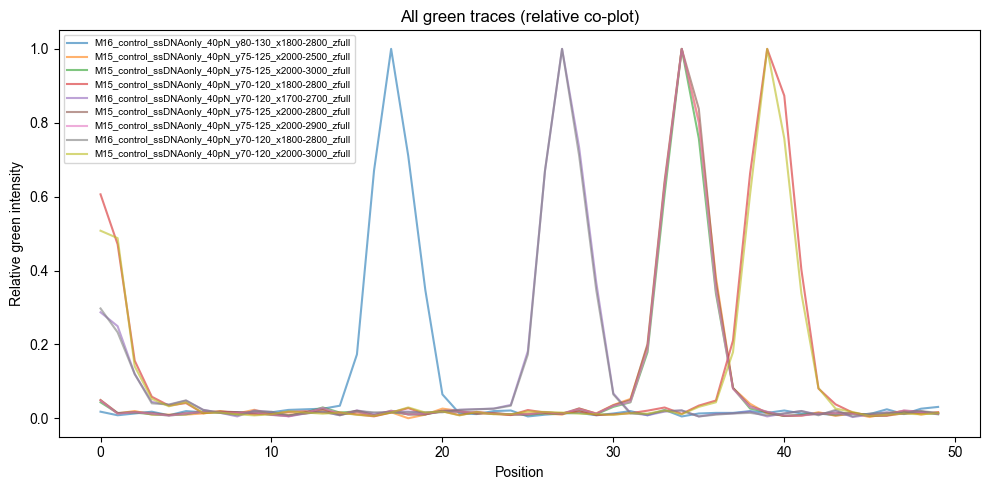

Saved to: ../results/coplot_green_relative.png


In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

csv_dir = "../results"
csv_files = glob.glob(os.path.join(csv_dir, "*rgb_intensity.csv"))

print(f"Found {len(csv_files)} CSV files")

plt.figure(figsize=(10, 5))

for csv_file in csv_files:
    df = pd.read_csv(csv_file)
    label = os.path.basename(csv_file).replace("_rgb_intensity.csv", "")

    green = df["green"].values
    green_rel = green / green.max() if green.max() != 0 else green

    plt.plot(df["index"], green_rel, label=label, alpha=0.6)

plt.xlabel("Position")
plt.ylabel("Relative green intensity")
plt.title("All green traces (relative co-plot)")
plt.legend(fontsize=7)
plt.tight_layout()

# ⬇️ saving
out_path = os.path.join(csv_dir, "coplot_green_relative.png")
plt.savefig(out_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved to: {out_path}")

### Peak detection — single window

Finds the red reference peak and all green binding peaks in a chosen time window, then reports their positions in µm relative to the red peak.

In [408]:
# --- parameters ---

#x_range = (0, 20)   # time frames to include
#y_range = None       # position crop (None = full)

green_threshold = 0.2   # peakutils threshold [0–1], lower = more sensitive
red_threshold   = 0.3
min_dist        = 1     # minimum peak separation (pixels)

# --- run ---
result = analyze_window(
    kymo,
    x_range=x_range,
    y_range=y_range,
    green_threshold=green_threshold,
    red_threshold=red_threshold,
    min_dist=min_dist,
    force_channel=file.force2x,
)

print(f"Pixel size:      {result['pixel_size_um']:.4f} µm/px")
print(f"Red ref peak:    px={result['red_peak_px']}  ({result['red_peak_um']:.3f} µm)")
print(f"Green peaks (px):  {result['green_peaks_px']}")
print(f"Green pos from red (px): {result['green_rel_px']}")
if result['green_rel_um'] is not None:
    print(f"Green pos from red (µm): {result['green_rel_um'].round(3)}")


Pixel size:      0.1000 µm/px
Red ref peak:    px=14  (1.400 µm)
Green peaks (px):  [34]
Green pos from red (px): [20]
Green pos from red (µm): [2.]


In [409]:
import os
png_name = f"{safe_basename}_{kymo_name}_x{x_range[0]}-{x_range[1]}_y{y_range[0] if y_range else 'full'}-{y_range[1] if y_range else 'full'}_peak_analysis.png"
png_path = os.path.join("../results", png_name)
plot_window_analysis(result, kymo_name=kymo_name, title_suffix=f"x={x_range}", save_path=png_path)
print(f"Saved → {png_path}")

Saved → ../results/2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-173315_Kymograph_M15_control_ssDNAonly_40pN_M15_control_ssDNAonly_40pN_x2000-2700_y75-125_peak_analysis.png


### Collect results across multiple windows

Repeat `analyze_window` for each time window you want to compare, collect the results, then export and visualise.

In [340]:
windows = [
    (1500,2500)
   
]
all_results = []
for xr in windows:


    try:
        res = analyze_window(
            kymo, x_range=xr, y_range=y_range,
            green_threshold=green_threshold,
            red_threshold=red_threshold,
            min_dist=min_dist,
            force_channel=file.force2x,
            red_peak_override=result['red_peak_px'],
            #red_peak_override=12,       ### if you want to force red peak to a specific pixel (e.g. if automatic detection fails), otherwise comment out

        )
        all_results.append(res)

        # Save plot for this window
        png_name = f"{safe_basename}_{kymo_name}_x{xr[0]}-{xr[1]}_peak_analysis.png"
        png_path = os.path.join("../results", png_name)
        plot_window_analysis(res, kymo_name=kymo_name,
                             title_suffix=f"x={xr}",
                             save_path=png_path)
        print(f"x={xr}  saved → {png_path}")
        print(f"       red_px={res['red_peak_px']}  green_rel_um={res['green_rel_um']}")
    except ValueError as e:
        print(f"x={xr}  SKIPPED: {e}")

x=(1500, 2500)  saved → ../results/4nM_90nt_Cy3oligo_1xPBS_40nM_MgCl2_400nM_ICP8_20260812-155326_Kymograph_M15_Ch3_ICPssDNA_thenCh5_highSalt_M15_Ch3_ICPssDNA_thenCh5_highSalt_x1500-2500_peak_analysis.png
       red_px=5  green_rel_um=[1.2 2.  2.4]


In [341]:
# Export to CSV — filename includes h5 base name and kymo name
csv_path, df_peaks = export_peak_analysis_csv(
    all_results,
    kymo_name=f"{safe_basename}_{kymo_name}",
)
print(f"Saved: {csv_path}")
df_peaks


Saved: ../results/4nM_90nt_Cy3oligo_1xPBS_40nM_MgCl2_400nM_ICP8_20260812-155326_Kymograph_M15_Ch3_ICPssDNA_thenCh5_highSalt_M15_Ch3_ICPssDNA_thenCh5_highSalt_peak_analysis.csv


,kymo_name,x_range,median_force_pN,red_peak_px,red_peak_orig_y_px,green_peak_px,green_peak_orig_y_px,green_pos_from_red_px,green_pos_from_red_um
0,4nM_90nt_Cy3oligo_1xPBS_40nM_MgCl2_400nM_ICP8_...,"(1500, 2500)",43.968689,5,75,17,87,12,1.2
1,4nM_90nt_Cy3oligo_1xPBS_40nM_MgCl2_400nM_ICP8_...,"(1500, 2500)",43.968689,5,75,25,95,20,2.0
2,4nM_90nt_Cy3oligo_1xPBS_40nM_MgCl2_400nM_ICP8_...,"(1500, 2500)",43.968689,5,75,29,99,24,2.4


###  Multiple kymograph comparison

Load all `*_peak_analysis.csv` files from the results folder and plot peak positions together. Run this cell after analysing every kymograph you want to compare.

In [235]:
import glob

csv_files = glob.glob("../results/*_peak_analysis.csv")
print(f"Found {len(csv_files)} peak-analysis CSVs")

import pandas as pd
df_all = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
print(df_all.shape)
df_all.head()


Found 16 peak-analysis CSVs
(92, 9)


,kymo_name,x_range,median_force_pN,red_peak_px,red_peak_orig_y_px,green_peak_px,green_peak_orig_y_px,green_pos_from_red_px,green_pos_from_red_um
0,2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-17142...,"(0, 500)",42.099889,14,89,27,102,13,1.3
1,2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-17142...,"(4500, 5500)",40.535035,14,89,23,98,9,0.9
2,2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-17142...,"(4500, 5500)",40.535035,14,89,33,108,19,1.9
3,2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-17142...,"(4500, 5500)",40.535035,14,89,39,114,25,2.5
4,2nM_60nt_ssDNA_2nM_MgCl2_gapped_20260806-17142...,"(8000, 8100)",40.465881,14,89,30,105,16,1.6


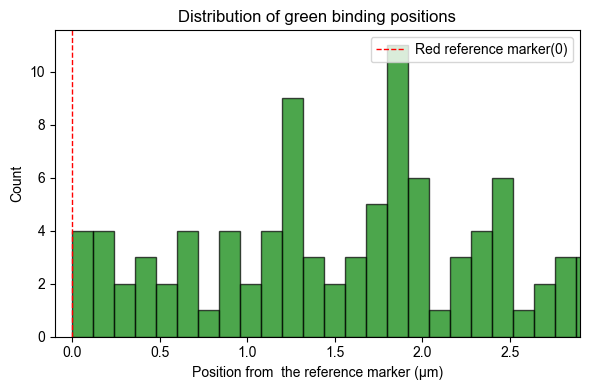

In [236]:
#plot_peak_comparison(df_all, title="Green binding positions relative to red reference")


plt.figure(figsize=(6, 4))
plt.hist(df_all["green_pos_from_red_um"].dropna(), bins=25, color="green", edgecolor="black", alpha=0.7)
plt.axvline(0, color="red", linestyle="--", linewidth=1, label="Red reference marker(0)")
plt.xlabel("Position from  the reference marker (µm)")
plt.ylabel("Count")
plt.title("Distribution of green binding positions")
plt.legend()
plt.xlim(-0.1, 2.9)
plt.tight_layout()
plt.show()

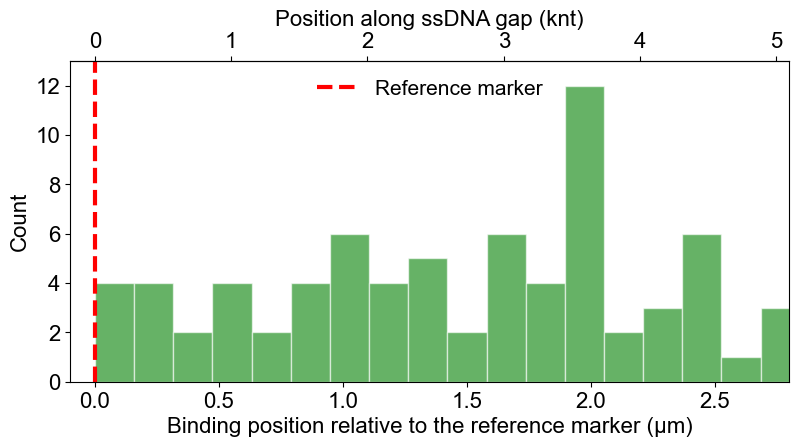

77


In [249]:
#FILETERED BY FORCE plot_peak_comparison(df_all, title="Green binding positions relative to red reference")
plt.rcParams['font.family'] = 'Arial'
df_filtered = df_all[
    (df_all["median_force_pN"] > 35) &
    (df_all["median_force_pN"] < 45)
]

plt.figure(figsize=(8, 4))
plt.hist(df_filtered["green_pos_from_red_um"].dropna(), bins=19, color="green", edgecolor="white", alpha=0.6)
plt.axvline(0, color="red", linestyle="--", linewidth=3, label="Reference marker")
plt.xlabel("Binding position relative to the reference marker (µm)", fontsize=16)
plt.ylabel("Count", fontsize=16)
#plt.title("Distribution of binding positions", fontsize=16)
plt.legend(fontsize=15,frameon=False)
plt.xlim(-0.1, 2.8)
plt.ylim(0,13)
plt.tight_layout()
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
#ax = plt.gca()
#ax.spines[['top', 'bottom', 'left', 'right']].set_linewidth(1.5)
ax = plt.gca()

secax = ax.secondary_xaxis(
    'top',
    functions=(lambda x: x*1.82, lambda x: x/1.82)
)

secax.set_xlabel('Position along ssDNA gap (knt)', fontsize=16)
secax.xaxis.set_tick_params(labelsize=16)   

#fig.savefig("figure.png", dpi=600, bbox_inches="tight")
plt.savefig("binding_histogram.png", dpi=600, bbox_inches="tight")

plt.show()
print(len(df_filtered))
#print(df_filtered)



# Association rate plot

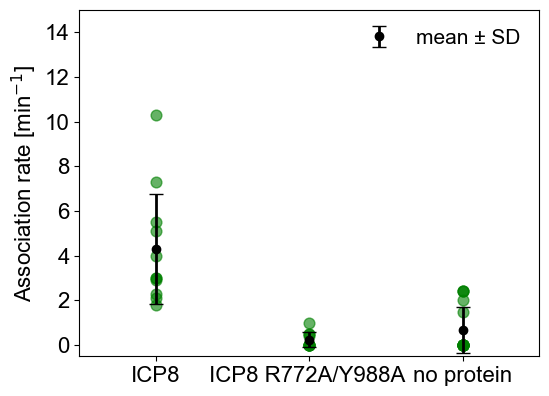

[np.float64(2.4790027320385404), np.float64(0.3292415526630866), np.float64(1.0116315720162157)]
[np.float64(4.3), np.float64(0.24), np.float64(0.6687500000000001)]
ICP8 vs ssDNA only: U=166.0, p=0.000074
ICP8 vs ICP8-R: U=110.0, p=0.000102
ssDNA only vs ICP8-R: U=83.0, p=0.876540


In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'


data = {
    10: [2.9, 1.8, 2.1, 3.0, 5.5, 7.3, 2.3, 5.1, 10.3, 3, 4],
    20: [1, 0, 0.5, 0.4, 0, 0, 0, 0, 0, 0.5],
    40: [2.4,0,0,0,0,0,0,0,0,0,0,0,2.4,1.5, 2.4, 2],
}



forces = sorted(data.keys())
labels = {
    10: "ICP8",
    40: "no protein",
    20: "ICP8 R772A/Y988A ",
}






forces = sorted(data.keys())
x_pos = [0, 1, 2]
means = [np.mean(data[f]) for f in forces]
stds  = [np.std(data[f]) for f in forces]

plt.figure(figsize=(5.5, 4))

for xi, f in zip(x_pos, forces):
    y = data[f]
    plt.scatter([xi] * len(y), y, color="green", s=60, zorder=5, alpha=0.6)

plt.errorbar(x_pos, means, yerr=stds, fmt="o", color="black",
             capsize=5, linewidth=2, zorder=5, label="mean ± SD")

plt.xticks(x_pos, [f"{f} pN" for f in forces])
plt.ylim(-0.5, 15)
plt.xlim(-0.5, 2.5)
plt.ylabel(r"Association rate [min$^{-1}$]", fontsize=16)



#plt.title("Annealing rate")
plt.legend(fontsize=15, frameon=False)
plt.tight_layout()

plt.xticks(
    x_pos,
    [labels[f] for f in forces],
    fontsize=16
)
plt.yticks(fontsize=16)
plt.savefig("annealing_rate.png", dpi=600, bbox_inches="tight")
plt.show()


print(stds)
print(means)

# two-sided tests
from scipy.stats import mannwhitneyu

icp8 = [2.9, 1.8, 2.1, 3.0, 5.5, 7.3, 2.3, 5.1, 10.3, 3, 4]
ssdna = [2.4,0,0,0,0,0,0,0,0,0,0,0,2.4,1.5,2.4,2]
icp8_r = [1, 0, 0.5, 0.4, 0, 0, 0, 0, 0, 0.5]

# two-sided tests
u, p = mannwhitneyu(icp8, ssdna, alternative='two-sided')
print(f"ICP8 vs ssDNA only: U={u:.1f}, p={p:.6f}")

u, p = mannwhitneyu(icp8, icp8_r, alternative='two-sided')
print(f"ICP8 vs ICP8-R: U={u:.1f}, p={p:.6f}")

u, p = mannwhitneyu(ssdna, icp8_r, alternative='two-sided')
print(f"ssDNA only vs ICP8-R: U={u:.1f}, p={p:.6f}")

# Plotting Force-Extension curves

Load force-extension curves as .csv files generated in LUMICKS Lakeview

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

cols = ["timestamp_ns", "Trap 2", "Distance 1"]

df_icp = pd.read_csv("/Users/arturkaczmarczyk/Desktop/FD_dna_ICP_LF.csv", skiprows=1, names=cols)
df_dna = pd.read_csv("/Users/arturkaczmarczyk/Desktop/FD_dna_LF.csv",     skiprows=1, names=cols)

plt.figure(figsize=(8, 5))
plt.plot(df_dna["Distance 1"], df_dna["Trap 2"], "o", markersize=2, alpha=0.5, label="DNA only")
plt.plot(df_icp["Distance 1"], df_icp["Trap 2"], "o", markersize=2, alpha=0.5, label="DNA + ICP8")
plt.xlabel("Extension (µm)")
plt.ylabel("Force (pN)")
plt.title("FD curves")
plt.legend()
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/Users/arturkaczmarczyk/Desktop/FD_dna_ICP_LF.csv'

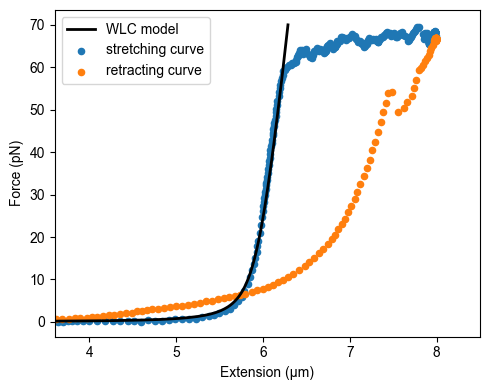

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M6_MakingGap_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)



# --------------------
# Data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

x_offset_um = 0.17  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(wlc_extension_um, forces, label="WLC model",color="black", linewidth=2)
ax.scatter(my_extension_um[:300] + x_offset_um, my_force_pN[:300], s=20, label=f"stretching curve")
ax.scatter(my_extension_um[300:] + x_offset_um, my_force_pN[300:], s=20, label=f"retracting curve")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(3.6, 8.5)

ax.set_ylabel("Force (pN)")
ax.legend()
plt.tight_layout()

plt.savefig("WLC_with_dataM6.png", dpi=600, bbox_inches="tight")
plt.savefig("WLC_with_dataM6.svg", bbox_inches="tight")
plt.show()

246


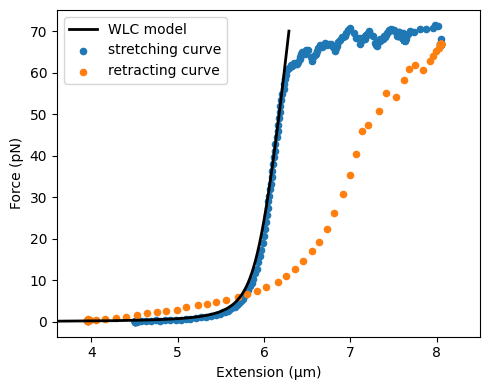

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M7_MakingGap_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)





# --------------------
# My data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

x_offset_um = 0.17  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))

vv = np.argmax(my_extension_um)

print(vv)
ax.plot(wlc_extension_um, forces, label="WLC model",color="black", linewidth=2)
#ax.scatter(my_extension_um[:250] + x_offset_um, my_force_pN[:250], s=20, label=f"stretching curve")
ax.scatter(my_extension_um[:vv] + x_offset_um, my_force_pN[:vv], s=20, label=f"stretching curve")
ax.scatter(my_extension_um[vv:] + x_offset_um, my_force_pN[vv:], s=20, label=f"retracting curve")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(3.6, 8.5)

ax.set_ylabel("Force (pN)")
ax.legend()
plt.tight_layout()

plt.savefig("WLC_with_dataM7.png", dpi=600, bbox_inches="tight")
plt.savefig("WLC_with_dataM7.svg", bbox_inches="tight")
plt.show()

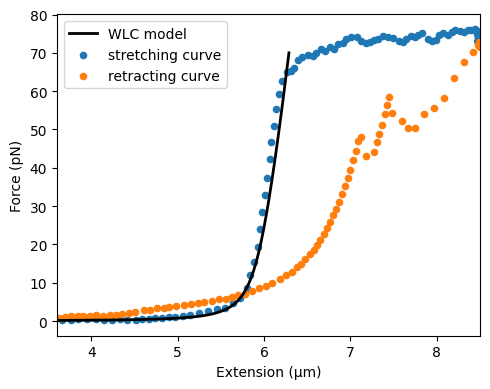

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq




import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M1_MakingGap_Day2_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)





# --------------------
# My data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

x_offset_um = 0.26  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))



ax.plot(wlc_extension_um, forces, label="WLC model",color="black", linewidth=2)
ax.scatter(my_extension_um[:200] + x_offset_um, my_force_pN[:200], s=20, label=f"stretching curve")
ax.scatter(my_extension_um[200:] + x_offset_um, my_force_pN[200:], s=20, label=f"retracting curve")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(3.6, 8.5)

ax.set_ylabel("Force (pN)")
ax.legend()
plt.tight_layout()

plt.savefig("WLC_with_dataM4_Day2.png", dpi=600, bbox_inches="tight")
plt.savefig("WLC_with_dataM4_Day2.svg", bbox_inches="tight")
plt.show()

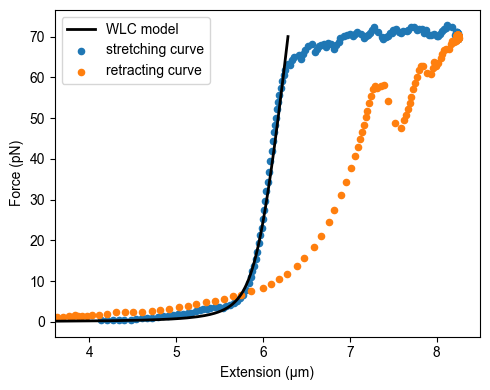

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq




import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M4_MakingGap_Day2_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)





# --------------------
# My data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

x_offset_um = 0.17  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))



ax.plot(wlc_extension_um, forces, label="WLC model",color="black", linewidth=2)
ax.scatter(my_extension_um[:250] + x_offset_um, my_force_pN[:250], s=20, label=f"stretching curve")
ax.scatter(my_extension_um[250:] + x_offset_um, my_force_pN[250:], s=20, label=f"retracting curve")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(3.6, 8.5)

ax.set_ylabel("Force (pN)")
ax.legend()
plt.tight_layout()

plt.savefig("WLC_with_dataM4_day2.png", dpi=600, bbox_inches="tight")
plt.savefig("WLC_with_dataM4_day2.svg", bbox_inches="tight")
plt.show()

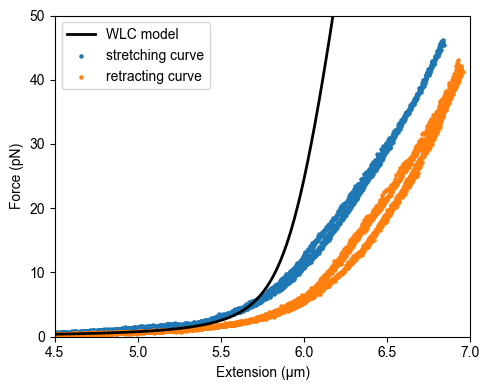

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq




import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M14_mutantCh3DNAonly_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)



df_hairpin2 = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M14_mutantCh5protein_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)


# --------------------
# My data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

my_extension_um2 = df_hairpin2["Distance 1"].values  # extension from experiment, µm
my_force_pN2 = df_hairpin2["Trap 2"].values    # force, pN

x_offset_um = 0  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))



ax.plot(wlc_extension_um, forces, label="WLC model",color="black", linewidth=2)
ax.scatter(my_extension_um + x_offset_um, my_force_pN, s=5, label=f"stretching curve")
ax.scatter(my_extension_um2 + x_offset_um, my_force_pN2, s=5, label=f"retracting curve")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(4.5, 7)

ax.set_ylabel("Force (pN)")
ax.set_ylim(0, 50)
ax.legend()
plt.tight_layout()

plt.savefig("WLC_with_dataM4_day2.png", dpi=600, bbox_inches="tight")
plt.savefig("WLC_with_dataM4_day2.svg", bbox_inches="tight")
plt.show()

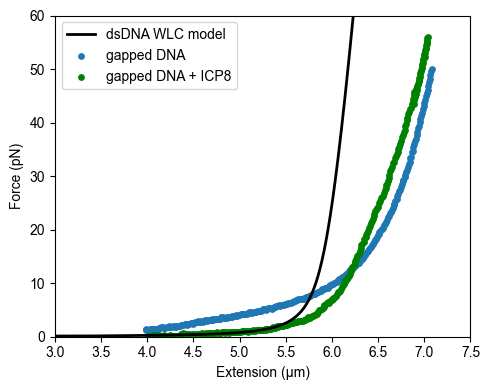

In [457]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq




import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M11_1stDay_relax_noProtein_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)



df_hairpin2 = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M11_1stDay_relax_WithProtein_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)


# --------------------
# Your data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

my_extension_um2 = df_hairpin2["Distance 1"].values  # extension from experiment, µm
my_force_pN2 = df_hairpin2["Trap 2"].values    # force, pN

x_offset_um = 0  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))



ax.plot(wlc_extension_um, forces, label="dsDNA WLC model",color="black", linewidth=2)
ax.scatter(my_extension_um + x_offset_um, my_force_pN, s=15, label=f"gapped DNA")
ax.scatter(my_extension_um2[:300] + x_offset_um, my_force_pN2[:300], s=15, color='green', label=f"gapped DNA + ICP8")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(3, 7.5)

ax.set_ylabel("Force (pN)")
ax.set_ylim(0, 60)
ax.legend()
plt.tight_layout()

plt.savefig("comparison_GAP.png", dpi=600, bbox_inches="tight")
plt.savefig("comparisonGap.svg", bbox_inches="tight")
plt.show()

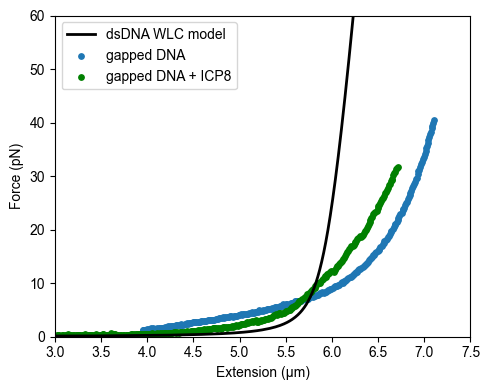

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq




import pandas as pd
import matplotlib.pyplot as plt

df_hairpin = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M6_1stDay_free_relax_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)



df_hairpin2 = pd.read_csv(
    "/Users/arturkaczmarczyk/Code/lumicks_pylake/data/M6_1stDay_ICP8_LF.csv",
    skiprows=1,
    names=["timestamp", "Trap 2", "Distance 1"]
    #names=["timestamp", "Force 2x", "Piezo Distance"]
)


# --------------------
# My data
# --------------------
my_extension_um = df_hairpin["Distance 1"].values  # extension from experiment, µm
my_force_pN = df_hairpin["Trap 2"].values    # force, pN

my_extension_um2 = df_hairpin2["Distance 1"].values  # extension from experiment, µm
my_force_pN2 = df_hairpin2["Trap 2"].values    # force, pN

x_offset_um = 0  # change this manually, e.g. -0.15, +0.25

# --------------------
# WLC model
# --------------------
bp = 17853
rise_per_bp = 0.34  # nm/bp
L = bp * rise_per_bp
P = 45.0
S = 1300.0
kBT = 4.114

def extension_for_force(F):
    def equation(x):
        z = x / L - F / S
        return (kBT / P) * (1 / (4 * (1 - z)**2) - 1/4 + z) - F

    return brentq(equation, 0, L * (1 + F/S) * 0.999999)

forces = np.linspace(0.01, 70, 500)
wlc_extension_um = np.array([extension_for_force(F) for F in forces]) / 1000

# --------------------
# Plot model + data
# --------------------
fig, ax = plt.subplots(figsize=(5, 4))



ax.plot(wlc_extension_um, forces, label="dsDNA WLC model",color="black", linewidth=2)
ax.scatter(my_extension_um + x_offset_um, my_force_pN, s=15, label=f"gapped DNA")
ax.scatter(my_extension_um2[:300] + x_offset_um, my_force_pN2[:300], s=15, color='green', label=f"gapped DNA + ICP8")


ax.set_xlabel("Extension (µm)")
ax.set_xlim(3, 7.5)

ax.set_ylabel("Force (pN)")
ax.set_ylim(0, 60)
ax.legend()
plt.tight_layout()

plt.savefig("comparison_GAP_M6.png", dpi=600, bbox_inches="tight")
plt.savefig("comparisonGap_M6.svg", bbox_inches="tight")
plt.show()